# My Ferrite.jl Manual  

## Import Packages

In [1]:
using SparseArrays
using Ferrite
using Plots 

We looked into manual pages of 

1. <i>shape_value</i>: return the value of shape function base_function evaluated in quadrature point q_point; 
2. <i>shape_gradient</i>: return the gradient of shape function base_function evaluated in quadrature point q_point

## Section 1: Introduction 

<b>Goal</b>: To provide a manual for Ferrite.jl to be used in the EE4375 and similar courses.  

## Section 2: Mesh Generation for a Line (1D) 
Here we show how to generate a (linear or quadratic) 1D mesh, traverse over the mesh and evaluate functions on the mesh. Ferrite stores the nodal coordinates as a Vector of Vector of dimension 1D, 2D and 3D depending on the spatial dimension.  

### Section 1.2: Loop over elements in the mesh 

In [53]:
# generate 1D grid for testing purposes 
nels  = (5,)        # number of elements in each spatial direction
left  = Vec((0.,))   # start point for geometry: lower-left point of the square 
right = Vec((1.,))   # end point for geometry: upper-right point of the square
#grid = generate_grid(Line, nels,left, right) 
grid = generate_grid(Line,nels,left,right)

Grid{1, Line, Float64} with 5 Line cells and 6 nodes

In [54]:
for node in grid.nodes display(node) end

Node{1, Float64}([0.0])

Node{1, Float64}([0.2])

Node{1, Float64}([0.4])

Node{1, Float64}([0.6])

Node{1, Float64}([0.8])

Node{1, Float64}([1.0])

In [55]:
for cell in grid.cells display(cell) end 

Line((1, 2))

Line((2, 3))

Line((3, 4))

Line((4, 5))

Line((5, 6))

In [56]:
for face in grid.facetsets display(face) end 

"left" => OrderedCollections.OrderedSet{FacetIndex}(FacetIndex[FacetIndex((1, 1))])

"right" => OrderedCollections.OrderedSet{FacetIndex}(FacetIndex[FacetIndex((5, 2))])

In [57]:
# below fails without definining the DofHandler 
for cell in grid.cells display(nodes(cell)) end 

LoadError: UndefVarError: `nodes` not defined

### Section 2.2: Obtaining Nodes Indices and Coordinates 
Below formds the basis of a 1D FEM code. Note that below works without setting up a quadrature rules. 

In [60]:
# here is how to obtain the nodes and the coordinates of the nodes 
order = 1
ip = Lagrange{RefLine, order}()
dh = DofHandler(grid)
# add of one field to prevent dh from being empty 
add!(dh, :u, ip)
close!(dh)

for cell_cache in CellIterator(dh)
    # 1. Get the indices of the nodes for this cell
    nodes = getnodes(cell_cache)  

    # 2. Get the physical coordinates for this cell 
    # (as a vector of Vec objects - one vector of coordinates per node)
    coords = getcoordinates(cell_cache) 
    
    # 3. Obtain the cellid of this cell 
    thiscellid = cellid(cell_cache)
    
    if (false)
        println("nodes = \n",nodes)
        println("cellid = \n", thiscellid) 
        println("x-coord of first  node of the cell\n", coords[1][1]) 
        println("x-coord of second node of the cell\n", coords[2][1]) 
        println("\n") 
    end 
    
end

### Section 3.2: Cell vs. CellCache 
Below the inguinity of the type system of Ferrite.jl is shown. 

In [21]:
order = 1
ip = Lagrange{RefLine, order}()
dh = DofHandler(grid)
# add of one field to prevent dh from being empty 
add!(dh, :u, ip)
close!(dh)

for cell_cache in CellIterator(dh)
        
    cell = getcells(dh.grid, cellid(cell_cache))
        
    println("typeof(cell_cache) = \n", typeof(cell_cache))
    println("typeof(cell)       = \n", typeof(cell))
            
end

typeof(cell_cache) = 
CellCache{Vec{1, Float64}, Grid{1, Line, Float64}, DofHandler{1, Grid{1, Line, Float64}}}
typeof(cell)       = 
Line
typeof(cell_cache) = 
CellCache{Vec{1, Float64}, Grid{1, Line, Float64}, DofHandler{1, Grid{1, Line, Float64}}}
typeof(cell)       = 
Line
typeof(cell_cache) = 
CellCache{Vec{1, Float64}, Grid{1, Line, Float64}, DofHandler{1, Grid{1, Line, Float64}}}
typeof(cell)       = 
Line
typeof(cell_cache) = 
CellCache{Vec{1, Float64}, Grid{1, Line, Float64}, DofHandler{1, Grid{1, Line, Float64}}}
typeof(cell)       = 
Line
typeof(cell_cache) = 
CellCache{Vec{1, Float64}, Grid{1, Line, Float64}, DofHandler{1, Grid{1, Line, Float64}}}
typeof(cell)       = 
Line


### Section 4.2: Obtaining shapefunction and shapefunctiongradient  

In [34]:
# generate 1D grid for testing purposes 
nels  = (5,)        # number of elements in each spatial direction
left  = Vec((0.,))   # start point for geometry: lower-left point of the square 
right = Vec((1.,))   # end point for geometry: upper-right point of the square
#grid = generate_grid(Line, nels,left, right) 
grid = generate_grid(Line,nels,left,right)

order = 1
ip = Lagrange{RefLine, order}()
qr = QuadratureRule{RefLine}(1)
cellvalues = CellValues(qr, ip);
dh = DofHandler(grid)
# add of one field to prevent dh from being empty 
add!(dh, :u, ip)
close!(dh)

for cell in CellIterator(dh)
    reinit!(cellvalues, cell)
    
    # Linear elements have a constant Jacobian, so we can just look at quadrature point 1
    q_point = 1 
    
    # 1. Get the Jacobian Matrix (Returns a 1×1 Tensor{1, 1, Float64})
    # Note: Ferrite relies on Tensors.jl for this type
    this_shape_value = Ferrite.shape_value(cellvalues,q_point,2)
    this_shape_grad  = Ferrite.shape_gradient(cellvalues,q_point,2)
    
    display(this_shape_value)
    display(this_shape_grad)
    
end

0.5

1-element Vec{1, Float64}:
 5.0

0.5

1-element Vec{1, Float64}:
 5.0

0.5

1-element Vec{1, Float64}:
 5.000000000000001

0.5

1-element Vec{1, Float64}:
 4.999999999999998

0.5

1-element Vec{1, Float64}:
 5.000000000000001

## Section 3: Mesh Generation for a Rectangle (2D) 

Here we explore the mesh generator that Ferrite provides. 

In [72]:
# use "methods(generate_grid)" to see alternative grid types  
methods(generate_grid)

# 29 methods for generic function "generate_grid" from Ferrite:
  [1] generate_grid(::Type{QuadraticLine}, nel::Tuple{Int64})
     @ ~/.julia/packages/Ferrite/Iyg5J/src/Grid/grid_generators.jl:42
  [2] generate_grid(::Type{QuadraticLine}, nel::Tuple{Int64}, left::Vec{1, T}) where T
     @ ~/.julia/packages/Ferrite/Iyg5J/src/Grid/grid_generators.jl:42
  [3] generate_grid(::Type{QuadraticLine}, nel::Tuple{Int64}, left::Vec{1, T}, right::Vec{1, T}) where T
     @ ~/.julia/packages/Ferrite/Iyg5J/src/Grid/grid_generators.jl:42
  [4] generate_grid(::Type{Line}, nel::Tuple{Int64})
     @ ~/.julia/packages/Ferrite/Iyg5J/src/Grid/grid_generators.jl:11
  [5] generate_grid(::Type{Line}, nel::Tuple{Int64}, left::Vec{1, T}) where T
     @ ~/.julia/packages/Ferrite/Iyg5J/src/Grid/grid_generators.jl:11
  [6] generate_grid(::Type{Line}, nel::Tuple{Int64}, left::Vec{1, T}, right::Vec{1, T}) where T
     @ ~/.julia/packages/Ferrite/Iyg5J/src/Grid/grid_generators.jl:11
  [7] generate_grid(::Type{QuadraticTriangle}, nel::Tuple{Int64, Int64}, LL::Vec{2, T}, LR::Vec{2, T}, UR::Vec{2, T}, UL::Vec{2, T}) where T
     @ ~/.julia/packages/Ferrite/Iyg5J/src/Grid/grid_generators.jl:427
  [8] generate_grid(::Type{Triangle}, nel::Tuple{Int64, Int64}, LL::Vec{2, T}, LR::Vec{2, T}, UR::Vec{2, T}, UL::Vec{2, T}) where T
     @ ~/.julia/packages/Ferrite/Iyg5J/src/Grid/grid_generators.jl:390
  [9] generate_grid(::Type{SerendipityQuadraticHexahedron}, nel::Tuple{Int64, Int64, Int64})
     @ ~/.julia/packages/Ferrite/Iyg5J/src/Grid/grid_generators.jl:332
 [10] generate_grid(::Type{SerendipityQuadraticHexahedron}, nel::Tuple{Int64, Int64, Int64}, left::Vec{3, T}) where T
     @ ~/.julia/packages/Ferrite/Iyg5J/src/Grid/grid_generators.jl:332
 [11] generate_grid(::Type{SerendipityQuadraticHexahedron}, nel::Tuple{Int64, Int64, Int64}, left::Vec{3, T}, right::Vec{3, T}) where T
     @ ~/.julia/packages/Ferrite/Iyg5J/src/Grid/grid_generators.jl:332
 [12] generate_grid(::Type{Pyramid}, nel::Tuple{Int64, Int64, Int64})
     @ ~/.julia/packages/Ferrite/Iyg5J/src/Grid/grid_generators.jl:271
 [13] generate_grid(::Type{Pyramid}, nel::Tuple{Int64, Int64, Int64}, left::Vec{3, T}) where T
     @ ~/.julia/packages/Ferrite/Iyg5J/src/Grid/grid_generators.jl:271
 [14] generate_grid(::Type{Pyramid}, nel::Tuple{Int64, Int64, Int64}, left::Vec{3, T}, right::Vec{3, T}) where T
     @ ~/.julia/packages/Ferrite/Iyg5J/src/Grid/grid_generators.jl:271
 [15] generate_grid(::Type{QuadraticQuadrilateral}, nel::Tuple{Int64, Int64}, LL::Vec{2, T}, LR::Vec{2, T}, UR::Vec{2, T}, UL::Vec{2, T}) where T
     @ ~/.julia/packages/Ferrite/Iyg5J/src/Grid/grid_generators.jl:139
 [16] generate_grid(::Type{Hexahedron}, nel::Tuple{Int64, Int64, Int64})
     @ ~/.julia/packages/Ferrite/Iyg5J/src/Grid/grid_generators.jl:177
 [17] generate_grid(::Type{Hexahedron}, nel::Tuple{Int64, Int64, Int64}, left::Vec{3, T}) where T
     @ ~/.julia/packages/Ferrite/Iyg5J/src/Grid/grid_generators.jl:177
 [18] generate_grid(::Type{Hexahedron}, nel::Tuple{Int64, Int64, Int64}, left::Vec{3, T}, right::Vec{3, T}) where T
     @ ~/.julia/packages/Ferrite/Iyg5J/src/Grid/grid_generators.jl:177
 [19] generate_grid(C::Type{Quadrilateral}, nel::Tuple{Int64, Int64}, LL::Vec{2, T}, LR::Vec{2, T}, UR::Vec{2, T}, UL::Vec{2, T}) where T
     @ ~/.julia/packages/Ferrite/Iyg5J/src/Grid/grid_generators.jl:103
 [20] generate_grid(C::Type{<:Ferrite.AbstractCell{<:Ferrite.AbstractRefShape{2}}}, nel::Tuple{Int64, Int64})
     @ ~/.julia/packages/Ferrite/Iyg5J/src/Grid/grid_generators.jl:94
 [21] generate_grid(C::Type{<:Ferrite.AbstractCell{<:Ferrite.AbstractRefShape{2}}}, nel::Tuple{Int64, Int64}, X::Array{Vec{2, T}, 1}) where T
     @ ~/.julia/packages/Ferrite/Iyg5J/src/Grid/grid_generators.jl:89
 [22] generate_grid(C::Type{<:Ferrite.AbstractCell{<:Ferrite.AbstractRefShape{2}}}, nel::Tuple{Int64, Int64}, left::Vec{2, T}) where T
     @ ~/.julia/packages/Ferrite/Iyg5J/src/Grid/grid_generators.jl:94
 [23] generate_grid(C::Type{<:Ferrite.Abstract

In [61]:
# generate coarse 2D grid for testing purposes 
nels  = (2, 2)            # number of elements in each spatial direction
left  = Vec((0.0, 0.0))   # start point for geometry: lower-left point of the square 
right = Vec((1.0, 1.0,))  # end point for geometry: upper-right point of the square
grid = generate_grid(Triangle, nels,left, right)
# grid = generate_grid(Quadrilateral, nels,left, right) 
# grid = generate_grid(QuadraticQuadrilateral, nels,left, right) 

Grid{2, Triangle, Float64} with 8 Triangle cells and 9 nodes

### Section 1.3: Loop over 2D elements in the mesh 

In [62]:
#dump(grid.nodes)

In [63]:
for node in grid.nodes display(node) end

Node{2, Float64}([0.0, 0.0])

Node{2, Float64}([0.5, 0.0])

Node{2, Float64}([1.0, 0.0])

Node{2, Float64}([0.0, 0.5])

Node{2, Float64}([0.5, 0.5])

Node{2, Float64}([1.0, 0.5])

Node{2, Float64}([0.0, 1.0])

Node{2, Float64}([0.5, 1.0])

Node{2, Float64}([1.0, 1.0])

In [64]:
for cell in grid.cells display(cell) end 

Triangle((1, 2, 4))

Triangle((2, 5, 4))

Triangle((2, 3, 5))

Triangle((3, 6, 5))

Triangle((4, 5, 7))

Triangle((5, 8, 7))

Triangle((5, 6, 8))

Triangle((6, 9, 8))

In [65]:
for face in grid.facetsets display(face) end 

"left" => OrderedCollections.OrderedSet{FacetIndex}(FacetIndex[FacetIndex((1, 3)), FacetIndex((5, 3))])

"bottom" => OrderedCollections.OrderedSet{FacetIndex}(FacetIndex[FacetIndex((1, 1)), FacetIndex((3, 1))])

"right" => OrderedCollections.OrderedSet{FacetIndex}(FacetIndex[FacetIndex((4, 1)), FacetIndex((8, 1))])

"top" => OrderedCollections.OrderedSet{FacetIndex}(FacetIndex[FacetIndex((6, 2)), FacetIndex((8, 2))])

### Section 2.3: Obtaining Nodes Indices and Coordinates

In [68]:
# here is how to obtain the nodes and the coordinates of the nodes 
order = 1
ip = Lagrange{RefTriangle, order}()
dh = DofHandler(grid)
# add of one field to prevent dh from being empty 
add!(dh, :u, ip)
close!(dh)

for cell_cache in CellIterator(dh)
    # 1. Get the indices of the nodes for this cell
    nodes = getnodes(cell_cache)  

    # 2. Get the physical coordinates for this cell 
    # (as a vector of Vec objects - one vector of coordinates per node)
    coords = getcoordinates(cell_cache) 
    
    # 3. Obtain the cellid of this cell 
    thiscellid = cellid(cell_cache)
    
    if (false)
        println("nodes = \n",nodes)
        println("cellid = \n", thiscellid) 
        println("x-coord of first  node of the cell\n", coords[1][1]) 
        println("x-coord of second node of the cell\n", coords[2][1]) 
        println("x-coord of third  node of the cell\n", coords[3][1]) 
        println("\n") 
    end 
    
end

### Section 3.3: Cell vs. CellCache

In [71]:
order = 1
ip = Lagrange{RefTriangle, order}()
dh = DofHandler(grid)
# add of one field to prevent dh from being empty 
add!(dh, :u, ip)
close!(dh)

for cell_cache in CellIterator(dh)
        
    cell = getcells(dh.grid, cellid(cell_cache))
    
    if (false)
       println("typeof(cell_cache) = \n", typeof(cell_cache))
       println("typeof(cell)       = \n", typeof(cell))
    end      
end

### Section 4.3: Obtaining shapefunction and shapefunctiongradient

In [51]:
# generate coarse 2D grid for testing purposes 
nels  = (2, 2)            # number of elements in each spatial direction
left  = Vec((0.0, 0.0))   # start point for geometry: lower-left point of the square 
right = Vec((1.0, 1.0,))  # end point for geometry: upper-right point of the square
grid = generate_grid(Triangle, nels,left, right)
# grid = generate_grid(Quadrilateral, nels,left, right) 
# grid = generate_grid(QuadraticQuadrilateral, nels,left, right) 

order = 1
ip = Lagrange{RefTriangle, order}()
qr = QuadratureRule{RefTriangle}(1)
cellvalues = CellValues(qr, ip);
dh = DofHandler(grid)
# add of one field to prevent dh from being empty 
add!(dh, :u, ip)
close!(dh)

for cell in CellIterator(dh)
    reinit!(cellvalues, cell)
    
    # Linear elements have a constant Jacobian, so we can just look at quadrature point 1
    q_point = 1 
    
    # 1. Get the Jacobian Matrix (Returns a 1×1 Tensor{1, 1, Float64})
    # Note: Ferrite relies on Tensors.jl for this type
    this_shape_value = Ferrite.shape_value(cellvalues,q_point,2)
    this_shape_grad  = Ferrite.shape_gradient(cellvalues,q_point,2)
    
    display(this_shape_value)
    display(this_shape_grad)
    
end

0.33333333333333

2-element Vec{2, Float64}:
 2.0
 0.0

0.33333333333333

2-element Vec{2, Float64}:
 2.0
 2.0

0.33333333333333

...

2-element Vec{2, Float64}:
 2.0
 2.0

0.33333333333333

2-element Vec{2, Float64}:
 2.0
 0.0

0.33333333333333

2-element Vec{2, Float64}:
 2.0
 2.0

### Section 5.3: Evaluate a function over the mesh 

In [15]:
# what is a single node 
node = grid.nodes[1]
dump(node)

Node{2, Float64}
  x: Vec{2, Float64}
    data: Tuple{Float64, Float64}
      1: Float64 0.0
      2: Float64 0.0


In [16]:
myf(node) = node.x[1]+node.x[2]
myf.(grid.nodes)

9-element Vector{Float64}:
 0.0
 0.5
 1.0
 0.5
 1.0
 1.5
 1.0
 1.5
 2.0

### Section 6.3:  Retrieving x-Coordinate of Two Nodes Attached to a Face (or Edge)
Examples of mesh connectivity. 

In [43]:
# generate grid 
grid = generate_grid(Quadrilateral, (3,3,))
# fix a FacetIndex 
fi = FacetIndex(4,2)
display(fi)
# retrieve facets constituting a cell 
display(getcells(grid, fi[1]))
# retrieve nodes constituting a facet 
Ferrite.facets(getcells(grid, fi[1]))[fi[2]]

FacetIndex((4, 2))

Quadrilateral((5, 6, 10, 9))

(6, 10)

## Section 4: Mesh Generation for a Rectangle in 3D

Here we explore the mesh generator that Ferrite provides.

In [74]:
nelem = 3 
nels  = (nelem, nelem, nelem) # number of elements in each spatial direction
left  = Vec((0., 0., 0.))    # start point for geometry 
right = Vec((1.0, 1.0, 1.0)) # end point for geometry
grid  = generate_grid(Tetrahedron,nels,left,right);

In [76]:
?RefTetrahedron

search: RefTetrahedron



```
RefTetrahedron <: AbstractRefShape{3}
```

Reference tetrahedron, reference dimension 3.

```
---------------------------------------+-------------------------
Vertex numbers:                        | Vertex coordinates:
             4                4        |
  ^ ξ₃      /  \             /| \      |  v1: 𝛏 = (0.0, 0.0, 0.0)
  |        /     \          / |   \    |  v2: 𝛏 = (1.0, 0.0, 0.0)
  +-> ξ₂  /        \       /  1___  \  |  v3: 𝛏 = (0.0, 1.0, 0.0)
 /       /      __--3     / /    __‾-3 |  v4: 𝛏 = (0.0, 0.0, 1.0)
ξ₁      2 __--‾‾         2/__--‾‾      |
---------------------------------------+-------------------------
Edge numbers:                          | Edge identifiers:
             +                +        | e1: (v1, v2)
            /  \             /| \      | e2: (v2, v3)
         5 /     \ 6      5 / |4  \ 6  | e3: (v3, v1)
          /        \       /  +__3  \  | e4: (v1, v4)
         /      __--+     / /1   __‾-+ | e5: (v2, v4)
        + __--‾‾2        +/__--‾‾2     | e6: (v3, v4)
---------------------------------------+-------------------------
Face numbers:                          | Face identifiers:
             +                +        |
            /  \             /| \      | f1: (v1, v3, v2)
           /     \          / | 4 \    | f2: (v1, v2, v4)
          /   3    \       /2 +___  \  | f3: (v2, v3, v4)
         /      __--+     / /  1 __‾-+ | f4: (v1, v4, v3)
        + __--‾‾         +/__--‾‾      |
---------------------------------------+-------------------------
```


### Section 1.3: Loop over 3D elements in the mesh 

In [77]:
for node in grid.nodes display(node) end

Node{3, Float64}([0.0, 0.0, 0.0])

Node{3, Float64}([0.3333333333333333, 0.0, 0.0])

Node{3, Float64}([0.6666666666666666, 0.0, 0.0])

Node{3, Float64}([1.0, 0.0, 0.0])

Node{3, Float64}([0.0, 0.3333333333333333, 0.0])

...

Node{3, Float64}([1.0, 0.6666666666666666, 1.0])

Node{3, Float64}([0.0, 1.0, 1.0])

Node{3, Float64}([0.3333333333333333, 1.0, 1.0])

Node{3, Float64}([0.6666666666666666, 1.0, 1.0])

Node{3, Float64}([1.0, 1.0, 1.0])

In [81]:
for cell in grid.cells display(cell) end 

Tetrahedron((1, 2, 5, 21))

Tetrahedron((1, 17, 2, 21))

Tetrahedron((2, 6, 5, 21))

Tetrahedron((2, 22, 6, 21))

Tetrahedron((2, 17, 18, 21))

...

Tetrahedron((43, 59, 44, 63))

Tetrahedron((44, 48, 47, 63))

Tetrahedron((44, 64, 48, 63))

Tetrahedron((44, 59, 60, 63))

Tetrahedron((44, 60, 64, 63))

In [79]:
for face in grid.facetsets display(face) end 

"left" => OrderedCollections.OrderedSet{FacetIndex}(FacetIndex[FacetIndex((1, 4)), FacetIndex((2, 2)), FacetIndex((19, 4)), FacetIndex((20, 2)), FacetIndex((37, 4)), FacetIndex((38, 2)), FacetIndex((55, 4)), FacetIndex((56, 2)), FacetIndex((73, 4)), FacetIndex((74, 2)), FacetIndex((91, 4)), FacetIndex((92, 2)), FacetIndex((109, 4)), FacetIndex((110, 2)), FacetIndex((127, 4)), FacetIndex((128, 2)), FacetIndex((145, 4)), FacetIndex((146, 2))])

"bottom" => OrderedCollections.OrderedSet{FacetIndex}(FacetIndex[FacetIndex((1, 1)), FacetIndex((3, 1)), FacetIndex((7, 1)), FacetIndex((9, 1)), FacetIndex((13, 1)), FacetIndex((15, 1)), FacetIndex((19, 1)), FacetIndex((21, 1)), FacetIndex((25, 1)), FacetIndex((27, 1)), FacetIndex((31, 1)), FacetIndex((33, 1)), FacetIndex((37, 1)), FacetIndex((39, 1)), FacetIndex((43, 1)), FacetIndex((45, 1)), FacetIndex((49, 1)), FacetIndex((51, 1))])

"right" => OrderedCollections.OrderedSet{FacetIndex}(FacetIndex[FacetIndex((16, 1)), FacetIndex((18, 1)), FacetIndex((34, 1)), FacetIndex((36, 1)), FacetIndex((52, 1)), FacetIndex((54, 1)), FacetIndex((70, 1)), FacetIndex((72, 1)), FacetIndex((88, 1)), FacetIndex((90, 1)), FacetIndex((106, 1)), FacetIndex((108, 1)), FacetIndex((124, 1)), FacetIndex((126, 1)), FacetIndex((142, 1)), FacetIndex((144, 1)), FacetIndex((160, 1)), FacetIndex((162, 1))])

"back" => OrderedCollections.OrderedSet{FacetIndex}(FacetIndex[FacetIndex((39, 3)), FacetIndex((40, 3)), FacetIndex((45, 3)), FacetIndex((46, 3)), FacetIndex((51, 3)), FacetIndex((52, 3)), FacetIndex((93, 3)), FacetIndex((94, 3)), FacetIndex((99, 3)), FacetIndex((100, 3)), FacetIndex((105, 3)), FacetIndex((106, 3)), FacetIndex((147, 3)), FacetIndex((148, 3)), FacetIndex((153, 3)), FacetIndex((154, 3)), FacetIndex((159, 3)), FacetIndex((160, 3))])

"top" => OrderedCollections.OrderedSet{FacetIndex}(FacetIndex[FacetIndex((113, 3)), FacetIndex((114, 3)), FacetIndex((119, 3)), FacetIndex((120, 3)), FacetIndex((125, 3)), FacetIndex((126, 3)), FacetIndex((131, 3)), FacetIndex((132, 3)), FacetIndex((137, 3)), FacetIndex((138, 3)), FacetIndex((143, 3)), FacetIndex((144, 3)), FacetIndex((149, 3)), FacetIndex((150, 3)), FacetIndex((155, 3)), FacetIndex((156, 3)), FacetIndex((161, 3)), FacetIndex((162, 3))])

"front" => OrderedCollections.OrderedSet{FacetIndex}(FacetIndex[FacetIndex((2, 1)), FacetIndex((5, 1)), FacetIndex((8, 1)), FacetIndex((11, 1)), FacetIndex((14, 1)), FacetIndex((17, 1)), FacetIndex((56, 1)), FacetIndex((59, 1)), FacetIndex((62, 1)), FacetIndex((65, 1)), FacetIndex((68, 1)), FacetIndex((71, 1)), FacetIndex((110, 1)), FacetIndex((113, 1)), FacetIndex((116, 1)), FacetIndex((119, 1)), FacetIndex((122, 1)), FacetIndex((125, 1))])

In [80]:
vtk_grid("prova", dh) do vtk
    vtk_point_data(vtk, dh, u, "u-computed")
end

LoadError: DeprecationError: The vtk interface has been updated in Ferrite v1.0. See https://github.com/Ferrite-FEM/Ferrite.jl/pull/692. Use VTKGridFile to open a vtk file, and the functions write_solution, write_cell_data, and write_projection to save data.

## Section 5: Reading Mesh from File using FerriteGmsh

1. use of the function togrid() to read mesh from file;
2. use of the functions getfacetset to find particular set of facets; 

## Section 6: How does Ferrite store the mesh

In [21]:
?Grid

search: Grid grid zgrid! ygrid! xgrid! VTKGridFile vtk_grid adapted_grid



```
Grid{dim, C<:AbstractCell, T<:Real} <: AbstractGrid}
```

A `Grid` is a collection of `Ferrite.AbstractCell`s and `Ferrite.Node`s which covers the computational domain. Helper structures for applying boundary conditions or define subdomains are gathered in `cellsets`, `nodesets`, `facetsets`, and `vertexsets`.

# Fields

  * `cells::Vector{C}`: stores all cells of the grid
  * `nodes::Vector{Node{dim,T}}`: stores the `dim` dimensional nodes of the grid
  * `cellsets::Dict{String, OrderedSet{Int}}`: maps a `String` key to an `OrderedSet` of cell ids
  * `nodesets::Dict{String, OrderedSet{Int}}`: maps a `String` key to an `OrderedSet` of global node ids
  * `facetsets::Dict{String, OrderedSet{FacetIndex}}`: maps a `String` to an `OrderedSet` of `FacetIndex`
  * `vertexsets::Dict{String, OrderedSet{VertexIndex}}`: maps a `String` key to an `OrderedSet` of `VertexIndex`


In [22]:
?addcellset!

search: addcellset! add_cell_entries!



```
addcellset!(grid::AbstractGrid, name::String, cellid::AbstractVecOrSet{Int})
addcellset!(grid::AbstractGrid, name::String, f::function; all::Bool=true)
```

Adds a cellset to the grid with key `name`. Cellsets are typically used to define subdomains of the problem, e.g. two materials in the computational domain. The `DofHandler` can construct different fields which live not on the whole domain, but rather on a cellset. `all=true` implies that `f(x)` must return `true` for all nodal coordinates `x` in the cell if the cell should be added to the set, otherwise it suffices that `f(x)` returns `true` for one node.

```julia
addcellset!(grid, "left", Set((1,3))) #add cells with id 1 and 3 to cellset left
addcellset!(grid, "right", x -> norm(x[1]) < 2.0 ) #add cell to cellset right, if x[1] of each cell's node is smaller than 2.0
```


In [23]:
?getcellset

search: getcellset getcells getncells getcelltype



```
getcellset(grid::AbstractGrid, setname::String)
```

Returns all cells as cellid in the set with name `setname`.


## Section 7: Initializing cellvalues using the CellValues() function 
 
The <i>CellValues</i> object facilitates the process of evaluating values of shape functions in the finite element cell. The <i>CellValues()</i> function has an optional third argument that is instance of a Interpolation which is used to interpolate the geometry.

In [24]:
?CellValues

search: CellValues CellVectorValues CellScalarValues AbstractCellValues



```
CellValues([::Type{T},] quad_rule::QuadratureRule, func_interpol::Interpolation, [geom_interpol::Interpolation])
```

A `CellValues` object facilitates the process of evaluating values of shape functions, gradients of shape functions, values of nodal functions, gradients and divergences of nodal functions etc. in the finite element cell.

**Arguments:**

  * `T`: an optional argument (default to `Float64`) to determine the type the internal data is stored as.
  * `quad_rule`: an instance of a [`QuadratureRule`](@ref)
  * `func_interpol`: an instance of an [`Interpolation`](@ref) used to interpolate the approximated function
  * `geom_interpol`: an optional instance of a [`Interpolation`](@ref) which is used to interpolate the geometry. By default linear Lagrange interpolation is used. For embedded elements the geometric interpolations should be vectorized to the spatial dimension.

**Keyword arguments:** The following keyword arguments are experimental and may change in future minor releases

  * `update_gradients`: Specifies if the gradients of the shape functions should be updated (default true)
  * `update_hessians`: Specifies if the hessians of the shape functions should be updated (default false)
  * `update_detJdV`: Specifies if the volume associated with each quadrature point should be updated (default true)

**Common methods:**

  * [`reinit!`](@ref)
  * [`getnquadpoints`](@ref)
  * [`getdetJdV`](@ref)
  * [`shape_value`](@ref)
  * [`shape_gradient`](@ref)
  * [`shape_symmetric_gradient`](@ref)
  * [`shape_divergence`](@ref)
  * [`function_value`](@ref)
  * [`function_gradient`](@ref)
  * [`function_symmetric_gradient`](@ref)
  * [`function_divergence`](@ref)
  * [`spatial_coordinate`](@ref)


In [25]:
#?QuadratureRule

In [26]:
dim = 2
order = 1
ip = Lagrange{RefQuadrilateral, order}()
qr = QuadratureRule{RefQuadrilateral}(2*order+1)
cellvalues = CellValues(qr, ip);

In [27]:
#dump(cellvalues)

In [28]:
nqp = getnquadpoints(cellvalues)
for (cell_num, cell) in enumerate(CellIterator(dh))
    dof_range_u = dof_range(dh,:u)
    uloc = celldofs(dh,cell_num)[dof_range_u] 
    Ferrite.reinit!(cellvalues, cell)

    for q_point in 1:nqp
        velocity = function_value(cvu, q_point, uloc)
        # display(velocity)
    end
end

LoadError: UndefVarError: `dh` not defined

## Section 8: Initialize DOF Handler and Loop over Elements 
Requires extension to describe the constraint handler. 

In [29]:
nels  = (3, 3)            # number of elements in each spatial direction
left  = Vec((0.0, 0.0))   # start point for geometry: lower-left point of the square 
right = Vec((1.0, 1.0,))  # end point for geometry: upper-right point of the square
grid = generate_grid(Quadrilateral, nels,left, right) 

dh = DofHandler(grid)
add!(dh, :u, ip)
close!(dh);

In [30]:
dh

DofHandler{2, Grid{2, Quadrilateral, Float64}}
  Fields:
    :u, Lagrange{RefQuadrilateral, 1}()
  Dofs per cell: 4
  Total dofs: 16

In [31]:
?getcellset

search: getcellset getcells getncells getcelltype



```
getcellset(grid::AbstractGrid, setname::String)
```

Returns all cells as cellid in the set with name `setname`.


In [32]:
# loop over elements and retrieve coordinate of the nodes of each cell 
for cell in CellIterator(dh)
    data = cellid(cell)
    display(data)
end

1

2

3

4

5

6

7

8

9

In [33]:
# loop over quadrature points in all cells 
for (cellcount, cell) in enumerate(CellIterator(dh))
    coords = getcoordinates(cell)
    # display(coords)
    reinit!(cellvalues, cell)
    for q_point in 1:getnquadpoints(cellvalues)
        coords_qp = spatial_coordinate(cellvalues, q_point, coords)
        # display(coords_qp) 
     end
end

### Section 1.8: Sub-DOF Handler
How do find indices of fields? 

In [34]:
dof_range(dh,:u)

1:4

In [35]:
?DofOrder.FieldWise()

```
DofOrder.FieldWise()
DofOrder.FieldWise(target_blocks::Vector{Int})
```

Dof order passed to [`renumber!`](@ref) to renumber global dofs field wise resulting in a globally blocked system.

The default behavior is to group dofs of each field into their own block, with the same order as in the DofHandler. This can be customized by passing a vector of the same length as the total number of fields in the DofHandler (see `getfieldnames(dh)`) that maps each field to a "target block": to renumber a DofHandler with three fields `:u`, `:v`, `:w` such that dofs for `:u` and `:w` end up in the first global block, and dofs for `:v` in the second global block use `DofOrder.FieldWise([1, 2, 1])`.

This renumbering is stable such that the original relative ordering of dofs within each target block is maintained.


In [36]:
DofOrder.FieldWise(:u)

LoadError: MethodError: no method matching iterate(::Symbol)

[0mClosest candidates are:
[0m  iterate([91m::Union{LinRange, StepRangeLen}[39m)
[0m[90m   @[39m [90mBase[39m [90m[4mrange.jl:880[24m[39m
[0m  iterate([91m::Union{LinRange, StepRangeLen}[39m, [91m::Integer[39m)
[0m[90m   @[39m [90mBase[39m [90m[4mrange.jl:880[24m[39m
[0m  iterate([91m::T[39m) where T<:Union{Base.KeySet{<:Any, <:Dict}, Base.ValueIterator{<:Dict}}
[0m[90m   @[39m [90mBase[39m [90m[4mdict.jl:698[24m[39m
[0m  ...


In [37]:
?renumber!

search: renumber!



```
renumber!(dh::AbstractDofHandler, order)
renumber!(dh::AbstractDofHandler, ch::ConstraintHandler, order)
```

Renumber the degrees of freedom in the DofHandler and/or ConstraintHandler according to the ordering `order`.

`order` can be given by one of the following options:

  * A permutation vector `perm::AbstractVector{Int}` such that dof `i` is renumbered to `perm[i]`.
  * [`DofOrder.FieldWise()`](@ref) for renumbering dofs field wise.
  * [`DofOrder.ComponentWise()`](@ref) for renumbering dofs component wise.
  * `DofOrder.Ext{T}` for "external" renumber permutations, see documentation for `DofOrder.Ext` for details.

!!! warning
    The dof numbering in the DofHandler and ConstraintHandler *must always be consistent*. It is therefore necessary to either renumber *before* creating the ConstraintHandler in the first place, or to renumber the DofHandler and the ConstraintHandler *together*.



In [38]:
dd = renumber!(dh, DofOrder.FieldWise() )

In [39]:
celldofs(dh,4)

4-element Vector{Int64}:
  4
  3
  9
 10

In [40]:
sdh = dh.subdofhandlers[1]
# getfieldnames(sdh)                     # does not work yet 
field_idx = find_field(dh, :u) # does not work yet

LoadError: UndefVarError: `find_field` not defined

In [41]:
function my_loop_dh(dh::DofHandler)

    for (sdh, ip_geo) in zip(dh.subdofhandlers, ip_geos)
        field_idx = find_field(sdh, fieldname)
        ip_fun = getfieldinterpolation(sdh, field_idx)
    end
    return 0;
end

my_loop_dh (generic function with 1 method)

In [42]:
my_loop_dh(dh)

LoadError: UndefVarError: `ip_geos` not defined

### Use of the function apply_analytical() to set the initial condition

In [43]:
function find_field(dh::DofHandler, field_name::Symbol)
    for (sdh_idx, sdh) in pairs(dh.subdofhandlers)
        field_idx = _find_field(sdh, field_name)
        !isnothing(field_idx) && return (sdh_idx, field_idx)
    end
    error("Did not find field :$field_name in DofHandler (existing fields: $(getfieldnames(dh))).")
end
"""
    _find_field(sdh::SubDofHandler, field_name::Symbol)::Int

Return the index of the field with name `field_name` in the `SubDofHandler` `sdh`. Return
`nothing` if the field is not found.

See also: [`find_field(dh::DofHandler, field_name::Symbol)`](@ref), [`find_field(sdh::SubDofHandler, field_name::Symbol)`](@ref).
"""
function _find_field(sdh::SubDofHandler, field_name::Symbol)
    return findfirst(x -> x === field_name, sdh.field_names)
end

_find_field

In [44]:
function apply_analytical!(
        a::AbstractVector, dh::DofHandler, fieldname::Symbol, f::Function,
        cellset = 1:getncells(get_grid(dh))
    )

    fieldname ∉ getfieldnames(dh) && error("The fieldname $fieldname was not found in the dof handler")
    ip_geos = _geometric_interpolations(dh)

    for (sdh, ip_geo) in zip(dh.subdofhandlers, ip_geos)
        isnothing(_find_field(sdh, fieldname)) && continue
        field_idx = find_field(sdh, fieldname)
        ip_fun = getfieldinterpolation(sdh, field_idx)
        field_dim = n_components(sdh, field_idx)
        celldofinds = dof_range(sdh, fieldname)
        set_intersection = if length(cellset) == length(sdh.cellset) == getncells(get_grid(dh))
            BitSet(1:getncells(get_grid(dh)))
        else
            intersect(BitSet(sdh.cellset), BitSet(cellset))
        end
        isempty(set_intersection) && continue
        _apply_analytical!(a, dh, celldofinds, field_dim, ip_fun, ip_geo, f, set_intersection)
    end
    return a
end

function _apply_analytical!(
        a::AbstractVector, dh::AbstractDofHandler, celldofinds, field_dim,
        ip_fun::Interpolation{RefShape}, ip_geo::Interpolation, f::Function, cellset
    ) where {dim, RefShape <: AbstractRefShape{dim}}

    coords = getcoordinates(get_grid(dh), first(cellset))
    ref_points = reference_coordinates(ip_fun)
    dummy_weights = zeros(length(ref_points))
    qr = QuadratureRule{RefShape}(dummy_weights, ref_points)
    # Note: Passing ip_geo as the function interpolation here, it is just a dummy.
    cv = CellValues(qr, ip_geo, ip_geo)
    c_dofs = celldofs(dh, first(cellset))
    f_dofs = zeros(Int, length(celldofinds))

    # Check f before looping
    length(f(first(coords))) == field_dim || error("length(f(x)) must be equal to dimension of the field ($field_dim)")

    for cellnr in cellset
        getcoordinates!(coords, get_grid(dh), cellnr)
        celldofs!(c_dofs, dh, cellnr)
        for (i, celldofind) in enumerate(celldofinds)
            f_dofs[i] = c_dofs[celldofind]
        end
        _apply_analytical!(a, f_dofs, coords, field_dim, cv, f)
    end
    return a
end

function _apply_analytical!(a::AbstractVector, dofs::Vector{Int}, coords::Vector{<:Vec}, field_dim, cv::CellValues, f)
    for i_dof in 1:getnquadpoints(cv)
        x_dof = spatial_coordinate(cv, i_dof, coords)
        for (idim, icval) in enumerate(f(x_dof))
            a[dofs[field_dim * (i_dof - 1) + idim]] = icval
        end
    end
    return a
end

LoadError: UndefVarError: `AbstractRefShape` not defined

In [47]:
nelem = 50
H = 0.25; L = 4*H 
nels  = (4*nelem, nelem) # number of elements in each spatial direction
left  = Vec((0., 0.))    # start point for geometry 
right = Vec((L, H,)) # end point for geometry
grid = generate_grid(Quadrilateral,nels,left,right);

dim = 2 
degree = 2

# Interpolations
ipu = Lagrange{RefQuadrilateral,degree+1}() ^ dim # quadratic for 3 velocity components 
ipp = Lagrange{RefQuadrilateral,degree}()         # linear for scalar pressure 

# Dofs
dh = DofHandler(grid)
add!(dh, :u, ipu)
add!(dh, :p, ipp)
close!(dh) 

uinit = zeros(ndofs(dh))
apply_analytical!(uinit, dh, :p, x -> (x[1]^2 - 1) * (x[2]^2 - 1)); # init condition for pressure 
# apply_analytical!(uinit, dh, :u, x -> [x[2]*sin(pi*x[1]), x[1]*cos(pi*x[2])]); # init condition for velocity 

VTKGridFile("stokes_2d_channel_init", dh) do vtk
    write_solution(vtk, dh, uinit)
end

LoadError: UndefVarError: `get_grid` not defined

In [46]:
?apply_analytical!

search: apply_analytical! _apply_analytical!



No documentation found.

`apply_analytical!` is a `Function`.

```
# 2 methods for generic function "apply_analytical!" from Main:
 [1] apply_analytical!(a::AbstractVector, dh::DofHandler, fieldname::Symbol, f::Function)
     @ In[44]:1
 [2] apply_analytical!(a::AbstractVector, dh::DofHandler, fieldname::Symbol, f::Function, cellset)
     @ In[44]:1
```


### Section 2.8: What does re-init do? 

In [117]:
#?reinit!

### Section 3.8: How to get coords and coord_qp?
Obtain coordinates of quadrature points in each cell by 
1. loop over cells in the mesh using CellIterator(dh), where dh = DofHandler(grid);
2. for each cell, retrieve the coordinates for each cell using getcoordinates() yielding coord as output; 
3. reinit cellvalues for each cell using reinit!;   
4. loop over quad points of cell and retrieve spatial coordinate for each quad point in the cell using spatial_coordinate() and coords as input; 

###  Section 4.8: What is RefCube? What are alternative values? 

In [118]:
methods(QuadratureRule)

# 0 methods for type constructor

### Section 5.8: apply! vs. apply_rhs! vs. apply_zero? vs. apply_local! vs. apply_assemble! for boundary conditions 

<b>apply!()</b>
1. apply!(K,f,ch): adjust K and f for Dirichlet boundary conditions specified in ch; 
2. apply!(v,ch): Dirichlet boundary conditions and affine constraints, specified in ch, to the solution vector v; 

<b>apply!_rhs()</b>
1. applies the boundary condition to the right-hand-side vector without modifying the stiffness matrix;

<b>apply!_zero()</b>
Typically used in e.g. a Newton solver where the increment, du, should be prescribed to zero even for non-homogeneouos boundary conditions; 

<b>apply_local!()</b>
Condensation of constrained degrees-of-freedom locally in local_matrix and local_vector before they are to be assembled into the global system;

<b>apply_assemble!()</b>
similar to using apply_local! followed by assemble!; 

In [119]:
?apply!

search: apply! apply_rhs! apply_zero! apply_local! apply_assemble!



```
apply!(K::SparseMatrixCSC, rhs::AbstractVector, ch::ConstraintHandler)
```

Adjust the matrix `K` and right hand side `rhs` to account for the Dirichlet boundary conditions specified in `ch` such that `K \ rhs` gives the expected solution.

!!! note
    `apply!(K, rhs, ch)` essentially calculates

    ```julia
    rhs[free] = rhs[free] - K[constrained, constrained] * a[constrained]
    ```

    where `a[constrained]` are the inhomogeneities. Consequently, the sign of `rhs` matters (in contrast with `apply_zero!`).


```julia
apply!(v::AbstractVector, ch::ConstraintHandler)
```

Apply Dirichlet boundary conditions and affine constraints, specified in `ch`, to the solution vector `v`.

# Examples

```julia
K, f = assemble_system(...) # Assemble system
apply!(K, f, ch)            # Adjust K and f to account for boundary conditions
u = K \ f                   # Solve the system, u should be "approximately correct"
apply!(u, ch)               # Explicitly make sure bcs are correct
```

!!! note
    The last operation is not strictly necessary since the boundary conditions should already be fulfilled after `apply!(K, f, ch)`. However, solvers of linear systems are not exact, and thus `apply!(u, ch)` can be used to make sure the boundary conditions are fulfilled exactly.



### Section 6.8: assemble! vs. apply_assemble! 
The function apply_assemble!() can write to entries of the global matrix and vector outside of the indices in global_dofs. 

## Section 9: Constraint Handler 

Using the constraint handler ch. Data type with one member per boundary condition. 

## Section 10: Keyword coupling=coupling 

- Q1: what is the importance of coupling=coupling in K = allocate_matrix(dh,ch; coupling=coupling)?
- A1: It is only an optimization to not store entries in the global matrix that will always be 0
  
- Q2: Does the kind of coupling intended here change in case of periodic boundary conditions, as in e.g. the Stokes tuturial?
- A2: Coupling due to constraints are handled separately and the coupling keyword don't influence that (coupling is only used for coupling between the fields in the "bulk" domain if that make sense)

- Q3: Does the importance of coupling grow in case of flow coupled with a set of coupled convection - diffusion - reaction equations?
- A3: By default Ferrite assumes all fields couple with all fields so if you don't specify coupling at all you are safe. If you know some fields don't couple you can use coupling as an optimization.

## Section 11: Updating Vectors and Matrices within Non-Linear or Time Loop

What is the difference between <i>apply!</i>, <i>apply_rhs!</i> and <i>update!</i>. 

## Section 12: Mesh Convergence for the 1D Poisson Equation

In [14]:
# define spatially varying diffusion coefficient 
function my_diff_coeff(x)
    return 1.  
end 

# define spatially varying source functin 
function my_source(x)
    #return -pi^2*x[1]*(x[1]-1)*sin(pi*x[1])+2*pi*x[1]*cos(pi*x[1])+2*pi*(x[1]-1)*cos(pi*x[1])+2*sin(pi*x[1])
    return (x[1]<=.1)*(x[1]<=.2)
end 

# Ke: added spatially varying diffusion coefficient 
# fe: forces zero source term 
function assemble_element!(Ke::Matrix, fe::Vector, cellvalues::CellValues, mycoords)
    n_basefuncs = getnbasefunctions(cellvalues)
    # Reset to 0
    fill!(Ke, 0)
    fill!(fe, 0)
    # Loop over quadrature points
    for q_point in 1:getnquadpoints(cellvalues)
        # Get the quadrature weight
        dΩ = getdetJdV(cellvalues, q_point)
        # ADDED: Get coord of quadrature point
        coords_qp = spatial_coordinate(cellvalues, q_point, mycoords)
        # ADDED: Evaluate spatially dependent diffusion coefficient in quad point 
        val_diff_coeff = my_diff_coeff(coords_qp)
        # ADDED: Evaluate spatially dependent source term in quad point 
        val_source = my_source(coords_qp)        
        # Loop over test shape functions
        for i in 1:n_basefuncs
            δu  = shape_value(cellvalues, q_point, i)
            ∇δu = shape_gradient(cellvalues, q_point, i)
            # Add contribution to fe
            fe[i] += val_source * δu * dΩ
            # Loop over trial shape functions
            for j in 1:n_basefuncs
                ∇u = shape_gradient(cellvalues, q_point, j)
                # MODIFIED: Add contribution to Ke
                Ke[i, j] += val_diff_coeff * (∇δu ⋅ ∇u) * dΩ
            end
        end
    end
    return Ke, fe
end

assemble_element! (generic function with 1 method)

In [15]:
function assemble_global(cellvalues::CellValues, K::SparseMatrixCSC, dh::DofHandler)
    # Allocate the element stiffness matrix and element force vector
    n_basefuncs = getnbasefunctions(cellvalues)
    Ke = zeros(n_basefuncs, n_basefuncs)
    fe = zeros(n_basefuncs)
    # Allocate global force vector f
    f = zeros(ndofs(dh))
    # Create an assembler
    assembler = start_assemble(K, f)
    # Loop over all cels
    for cell in CellIterator(dh)
        # Added: Get coordinates from current cell 
        coords = getcoordinates(cell)
        # Reinitialize cellvalues for this cell
        reinit!(cellvalues, cell)
        # Modified - Compute element contribution
        assemble_element!(Ke, fe, cellvalues, coords)
        # Assemble Ke and fe into K and f
        assemble!(assembler, celldofs(cell), Ke, fe)
    end
    return K, f
end

assemble_global (generic function with 1 method)

### First Order (Linear) Shape Functions   

Observe that: 
1. max-error-norm reduces quadratically with mesh size in case that low order quadrature is used; 
2. in case that high order quadrature rule is used, the max-error-norm reduces faster; 

In [16]:
?apply_analytical!

search: apply_analytical!



```
apply_analytical!(
    a::AbstractVector, dh::AbstractDofHandler, fieldname::Symbol,
    f::Function, cellset=1:getncells(get_grid(dh)))
```

Apply a solution `f(x)` by modifying the values in the degree of freedom vector `a` pertaining to the field `fieldname` for all cells in `cellset`. The function `f(x)` are given the spatial coordinate of the degree of freedom. For scalar fields, `f(x)::Number`, and for vector fields with dimension `dim`, `f(x)::Vec{dim}`.

This function can be used to apply initial conditions for time dependent problems.

!!! note
    This function only works for standard nodal finite element interpolations when the function value at the (algebraic) node is equal to the corresponding degree of freedom value. This holds for e.g. Lagrange and Serendipity interpolations, including sub- and superparametric elements.



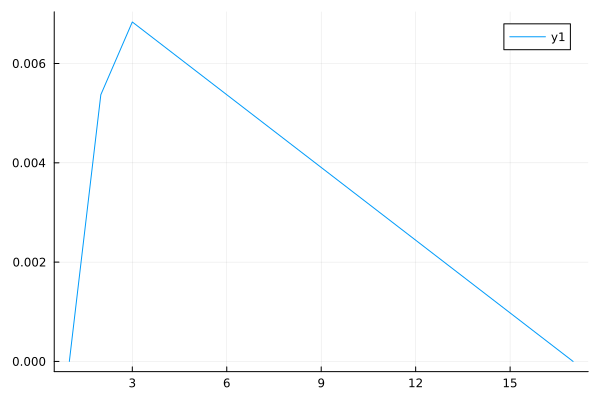

In [17]:
nels  = (16,)        # number of elements in each spatial direction
left  = Vec((0.,))   # start point for geometry: lower-left point of the square 
right = Vec((1.,))   # end point for geometry: upper-right point of the square
grid = generate_grid(Line,nels,left,right)

dim = 1
ip = Lagrange{RefLine, 1}()
qr = QuadratureRule{RefLine}(1)
cellvalues = CellValues(qr, ip);

dh = DofHandler(grid)
add!(dh, :u, ip)
close!(dh);

ch = ConstraintHandler(dh)

∂Ω = union(
    getfacetset(grid, "left"),
    getfacetset(grid, "right")
)

dbc = Dirichlet(:u, ∂Ω, (x, t) -> 0)
add!(ch, dbc)
close!(ch)

K = allocate_matrix(dh, ch) 

K, f = assemble_global(cellvalues, K, dh);

apply!(K, f, ch)
u = K \ f;

# initialize vector holding the analytical solution 
u_appl_analytical = zeros(ndofs(dh))

# set the analytical solution at the DOFS - note use of function with a bang 
apply_analytical!(u_appl_analytical, dh, :u, x -> -x[1]*(x[1]-1)*sin(pi*x[1]))

# set the analytical solution at the nodes - applies reordering - out is a matrix 
#u_appl_analytical_at_nodes = reshape_to_nodes(dh, u_appl_analytical, :u)

# set numerical solution at the nodes - applies reordering - out is a matrix
u_computed_at_nodes = evaluate_at_grid_nodes(dh, u, :u)

p1 = plot(u_computed_at_nodes)
#p2 = plot(u_appl_analytical_at_nodes[1,:])
#p3 = plot(abs.(u_computed_at_nodes[1,:]-u_appl_analytical_at_nodes[1,:]))
#plot(p1,p2,p3, layout = (3,1))
plot(p1)

In [18]:
?apply_analytical!

search: apply_analytical!



```
apply_analytical!(
    a::AbstractVector, dh::AbstractDofHandler, fieldname::Symbol,
    f::Function, cellset=1:getncells(get_grid(dh)))
```

Apply a solution `f(x)` by modifying the values in the degree of freedom vector `a` pertaining to the field `fieldname` for all cells in `cellset`. The function `f(x)` are given the spatial coordinate of the degree of freedom. For scalar fields, `f(x)::Number`, and for vector fields with dimension `dim`, `f(x)::Vec{dim}`.

This function can be used to apply initial conditions for time dependent problems.

!!! note
    This function only works for standard nodal finite element interpolations when the function value at the (algebraic) node is equal to the corresponding degree of freedom value. This holds for e.g. Lagrange and Serendipity interpolations, including sub- and superparametric elements.



In [7]:
?init_sparsity_pattern

search: init_sparsity_pattern



```
init_sparsity_pattern(dh::DofHandler; nnz_per_row::Int)
```

Initialize an empty [`SparsityPattern`](@ref) with `ndofs(dh)` rows and `ndofs(dh)` columns.

# Keyword arguments

  * `nnz_per_row`: memory optimization hint for the number of non-zero entries per row that will be added to the pattern.


In [8]:
sp = init_sparsity_pattern(dh; nnz_per_row=3)

17×17 SparsityPattern:
 - Sparsity: 100.0% (0 stored entries)
 - Entries per row (min, max, avg): 0, 0, 0.0
 - Memory estimate: 544 bytes used, 4.001 MiB allocated

### Second Order (Quadratic) Shape Functions

Observe that: 
1. error is smaller than first order elements 
2. max-error-norm reduces cubically with mesh size in case that appropriate order quadrature is used; 

In [56]:
nels  = (16,)        # number of elements in each spatial direction
left  = Vec((0.,))   # start point for geometry: lower-left point of the square 
right = Vec((1.,))   # end point for geometry: upper-right point of the square
grid = generate_grid(QuadraticLine,nels,left,right)

dim = 1
ip = Lagrange{dim, RefCube, 2}()
qr = QuadratureRule{dim, RefCube}(8)
cellvalues = CellScalarValues(qr, ip);

dh = DofHandler(grid)
add!(dh, :u, 1)
close!(dh);

K = create_sparsity_pattern(dh)

ch = ConstraintHandler(dh)

∂Ω = union(
    getfaceset(grid, "left"),
    getfaceset(grid, "right")
)

dbc = Dirichlet(:u, ∂Ω, (x, t) -> 0)
add!(ch, dbc)
close!(ch)

K, f = assemble_global(cellvalues, K, dh);

apply!(K, f, ch)
u = K \ f;

# define analytical solution 
u_anal(x::Vec) = -x[1]*(x[1]-1)*sin(pi*x[1])
u_anal(node::Node) = u_anal(node.x)

# initialize vector holding the analytical solution 
u_appl_analytical = zeros(ndofs(dh))

# set the analytical solution at the DOFS - note use of function with a bang 
apply_analytical!(u_appl_analytical, dh, :u, u_anal) 

# set the analytical solution at the nodes - applies reordering - out is a matrix 
u_appl_analytical_at_nodes = reshape_to_nodes(dh, u_appl_analytical, :u) 

# set numerical solution at the nodes - applies reordering - out is a matrix
u_computed_at_nodes = reshape_to_nodes(dh, u, :u)

p1 = plot(u_computed_at_nodes[1,:])
p2 = plot(u_appl_analytical_at_nodes[1,:])
p3 = plot(abs.(u_computed_at_nodes[1,:]-u_appl_analytical_at_nodes[1,:]))
plot(p1,p2,p3, layout = (3,1))

LoadError: DeprecationError: [31m`Lagrange{1, RefCube, 2}()`[39m is deprecated, use [32m`Lagrange{RefLine, 2}()`[39m instead.

## Section 13: Mesh Convergence for the 2D Poisson Equation 

In [57]:
# define spatially varying diffusion coefficient 
function my_diff_coeff(x)
    xbound = abs(x[1])<0.3
    ybound = abs(x[2])<0.1 
    inPlate = xbound*ybound
    inAir   = 1-inPlate
    return 1 # 4*pi*1e-6*(inAir+1/100*inPlate) 
end 

# define spatially varying source functin 
function my_source(x)
    return 2*pi^2*sin(pi*x[1])*sin(pi*x[2]) 
end 

# Ke: added spatially varying diffusion coefficient 
# fe: forces zero source term 
function assemble_element!(Ke::Matrix, fe::Vector, cellvalues::CellScalarValues, mycoords)
    n_basefuncs = getnbasefunctions(cellvalues)
    # Reset to 0
    fill!(Ke, 0)
    fill!(fe, 0)
    # Loop over quadrature points
    for q_point in 1:getnquadpoints(cellvalues)
        # Get the quadrature weight
        dΩ = getdetJdV(cellvalues, q_point)
        # ADDED: Get coord of quadrature point
        coords_qp = spatial_coordinate(cellvalues, q_point, mycoords)
        # ADDED: Evaluate spatially dependent diffusion coefficient in quad point 
        val_diff_coeff = my_diff_coeff(coords_qp)
        # ADDED: Evaluate spatially dependent source term in quad point 
        val_source = my_source(coords_qp)        
        # Loop over test shape functions
        for i in 1:n_basefuncs
            δu  = shape_value(cellvalues, q_point, i)
            ∇δu = shape_gradient(cellvalues, q_point, i)
            # Add contribution to fe
            fe[i] += val_source * δu * dΩ
            # Loop over trial shape functions
            for j in 1:n_basefuncs
                ∇u = shape_gradient(cellvalues, q_point, j)
                # MODIFIED: Add contribution to Ke
                Ke[i, j] += val_diff_coeff * (∇δu ⋅ ∇u) * dΩ
            end
        end
    end
    return Ke, fe
end

assemble_element! (generic function with 2 methods)

In [58]:
function assemble_global(cellvalues::CellScalarValues, K::SparseMatrixCSC, dh::DofHandler)
    # Allocate the element stiffness matrix and element force vector
    n_basefuncs = getnbasefunctions(cellvalues)
    Ke = zeros(n_basefuncs, n_basefuncs)
    fe = zeros(n_basefuncs)
    # Allocate global force vector f
    f = zeros(ndofs(dh))
    # Create an assembler
    assembler = start_assemble(K, f)
    # Loop over all cels
    for cell in CellIterator(dh)
        # Added: Get coordinates from current cell 
        coords = getcoordinates(cell)
        # Reinitialize cellvalues for this cell
        reinit!(cellvalues, cell)
        # Modified - Compute element contribution
        assemble_element!(Ke, fe, cellvalues, coords)
        # Assemble Ke and fe into K and f
        assemble!(assembler, celldofs(cell), Ke, fe)
    end
    return K, f
end

assemble_global (generic function with 2 methods)

### First Order (Linear) Shape Functions   

In [59]:
?apply_analytical!

search: apply_analytical! _apply_analytical!



No documentation found.

`apply_analytical!` is a `Function`.

```
# 2 methods for generic function "apply_analytical!" from Main:
 [1] apply_analytical!(a::AbstractVector, dh::DofHandler, fieldname::Symbol, f::Function)
     @ In[44]:1
 [2] apply_analytical!(a::AbstractVector, dh::DofHandler, fieldname::Symbol, f::Function, cellset)
     @ In[44]:1
```


In [60]:
nelem = 32
nels  = (nelem, nelem) # number of elements in each spatial direction
left  = Vec((0., 0.))    # start point for geometry 
right = Vec((1.0, 1.0,)) # end point for geometry
grid = generate_grid(Quadrilateral,nels,left,right);

dim = 2
ip = Lagrange{dim, RefCube, 1}()
qr = QuadratureRule{dim, RefCube}(4)
cellvalues = CellScalarValues(qr, ip);

dh = DofHandler(grid)
add!(dh, :u, 1)
close!(dh);

K = create_sparsity_pattern(dh)

ch = ConstraintHandler(dh)

∂Ω = union(
    getfaceset(grid, "left"),
    getfaceset(grid, "right"),
    getfaceset(grid, "top"),
    getfaceset(grid, "bottom"),
)

dbc = Dirichlet(:u, ∂Ω, (x, t) -> 0)
add!(ch, dbc)
close!(ch)

K, f = assemble_global(cellvalues, K, dh);

apply!(K, f, ch)
u = K \ f;

# initialize vector holding the analytical solution 
u_appl_analytical = zeros(ndofs(dh))

# set the analytical solution at the DOFS - note use of function with a bang 
# apply_analytical!(u_appl_analytical, dh, :u, u4_anal)
apply_analytical!(u_appl_analytical, dh, :u, x->sin(pi*x[1])*sin(pi*x[2]))

# set the analytical solution at the nodes - applies reordering - out is a matrix 
u_appl_analytical_at_nodes = reshape_to_nodes(dh, u_appl_analytical, :u)

# set numerical solution at the nodes - applies reordering - out is a matrix
u_computed_at_nodes = reshape_to_nodes(dh, u, :u)

p1 = plot(u_computed_at_nodes[1,:])
p2 = plot(u_appl_analytical_at_nodes[1,:])
p3 = plot(abs.(u_computed_at_nodes[1,:]-u_appl_analytical_at_nodes[1,:]))
plot(p1,p2,p3, layout = (3,1))
#plot(p3)

LoadError: DeprecationError: [31m`Lagrange{2, RefCube, 1}()`[39m is deprecated, use [32m`Lagrange{RefQuadrilateral, 1}()`[39m instead.

### Second Order (Quadratic) Shape Functions   

In [61]:
nelem = 16 
nels  = (nelem, nelem) # number of elements in each spatial direction
left  = Vec((0., 0.))    # start point for geometry 
right = Vec((1.0, 1.0,)) # end point for geometry
grid = generate_grid(QuadraticQuadrilateral,nels,left,right);

dim = 2
ip = Lagrange{dim, RefCube, 2}()
qr = QuadratureRule{dim, RefCube}(4)
cellvalues = CellScalarValues(qr, ip);

dh = DofHandler(grid)
add!(dh, :u, 1)
close!(dh);

K = create_sparsity_pattern(dh)

ch = ConstraintHandler(dh)

∂Ω = union(
    getfaceset(grid, "left"),
    getfaceset(grid, "right"),
    getfaceset(grid, "top"),
    getfaceset(grid, "bottom"),
)

dbc = Dirichlet(:u, ∂Ω, (x, t) -> 0)
add!(ch, dbc)
close!(ch)

K, f = assemble_global(cellvalues, K, dh);

apply!(K, f, ch)
u = K \ f;

# initialize vector holding the analytical solution 
u_appl_analytical = zeros(ndofs(dh))

# set the analytical solution at the DOFS - note use of function with a bang 
# apply_analytical!(u_appl_analytical, dh, :u, u4_anal)
apply_analytical!(u_appl_analytical, dh, :u, x->sin(pi*x[1])*sin(pi*x[2]))

# set the analytical solution at the nodes - applies reordering - out is a matrix 
u_appl_analytical_at_nodes = reshape_to_nodes(dh, u_appl_analytical, :u)

# set numerical solution at the nodes - applies reordering - out is a matrix
u_computed_at_nodes = reshape_to_nodes(dh, u, :u)

p1 = plot(u_computed_at_nodes[1,:])
p2 = plot(u_appl_analytical_at_nodes[1,:])
p3 = plot(abs.(u_computed_at_nodes[1,:]-u_appl_analytical_at_nodes[1,:]))
plot(p1,p2,p3, layout = (3,1))
#plot(p3)

LoadError: DeprecationError: [31m`Lagrange{2, RefCube, 2}()`[39m is deprecated, use [32m`Lagrange{RefQuadrilateral, 2}()`[39m instead.

## Section 14: Computing Fluxes

In [62]:
function my_get_coords(dh::DofHandler)
    # Loop over all cels
    for (cellcount, cell) in enumerate(CellIterator(dh))
        coords = getcoordinates(cell)
        display(coords)
        reinit!(cellvalues, cell)
        for q_point in 1:getnquadpoints(cellvalues)
            coords_qp = spatial_coordinate(cellvalues, q_point, coords)
            # display(my_diff_coeff(coords_qp)) 
        end
    end
    return 0
end

my_get_coords (generic function with 1 method)

In [63]:
# define spatially varying diffusion coefficient 
function my_diff_coeff(coord_qp)
    xbound = abs(coord_qp[1])<0.3
    ybound = abs(coord_qp[2])<0.2 
    inPlate = xbound*ybound
    inAir   = 1-inPlate
    return 4*pi*1e-6*(inAir+1/100*inPlate) 
end 

my_diff_coeff (generic function with 1 method)

In [ ]:
function compute_hfield(cellvalues::CellScalarValues{dim,T}, dh::DofHandler, a) where {dim,T}

    n = getnbasefunctions(cellvalues)
    cell_dofs = zeros(Int, n)
    nqp = getnquadpoints(cellvalues)

    # Allocate storage for the fluxes to store
    q = [Vec{2,T}[] for _ in 1:getncells(dh.grid)]

    for (cell_num, cell) in enumerate(CellIterator(dh))
        q_cell = q[cell_num]
        celldofs!(cell_dofs, dh, cell_num)
        aᵉ = a[cell_dofs]
        reinit!(cellvalues, cell)

        for q_point in 1:nqp
            q_qp = - function_gradient(cellvalues, q_point, aᵉ)
            push!(q_cell, q_qp)
        end
    end
    return q
end

function compute_bfield(cellvalues::CellScalarValues{dim,T}, dh::DofHandler, a) where {dim,T}

    n = getnbasefunctions(cellvalues)
    cell_dofs = zeros(Int, n)
    nqp = getnquadpoints(cellvalues)

    # Allocate storage for the fluxes to store
    q = [Vec{2,T}[] for _ in 1:getncells(dh.grid)]

    for (cell_num, cell) in enumerate(CellIterator(dh))
        q_cell = q[cell_num]
        celldofs!(cell_dofs, dh, cell_num)
        aᵉ = a[cell_dofs]
        reinit!(cellvalues, cell)
        coords = getcoordinates(cell)
        
        for q_point in 1:nqp
            coords_qp = spatial_coordinate(cellvalues, q_point, coords)
            val_diff_coeff = my_diff_coeff(coords_qp)
            q_qp = - val_diff_coeff*function_gradient(cellvalues, q_point, aᵉ)
            push!(q_cell, q_qp)
        end
    end
    return q
end

In [ ]:
h_gp = compute_hfield(cellvalues, dh, u);
b_gp = compute_bfield(cellvalues, dh, u);
#q_gp

In [ ]:
?L2Projector

In [ ]:
projector = L2Projector(ip, grid);
#projector 

In [ ]:
h_projected = project(projector, h_gp, qr; project_to_nodes=false);
b_projected = project(projector, b_gp, qr; project_to_nodes=false);
# q_projected

## Section 15: Exporting to VTK 

In [ ]:
#?vtk_point_data

In [ ]:
vtk_grid("2d_uniform_magn_plate", dh) do vtk
    vtk_point_data(vtk, dh, u, "Vm")
    vtk_point_data(vtk, projector, h_projected, "H")
    vtk_point_data(vtk, projector, b_projected, "B")
end

## Section 16: Advanced Topics 
1. Implementation of new basis functions. For Hermite basis functions for the bi-harmonic equation [pull request](https://github.com/Ferrite-FEM/Ferrite.jl/pull/1053/files). 